In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [15]:
import pandas as pd

df = pd.read_csv('Advertising.csv')
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [16]:
!pip install tensorflow


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\ASUS\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [17]:
!pip install pandas matplotlib scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\ASUS\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [19]:
# Load dataset
dataset = pd.read_csv('advertising.csv')

# Lihat beberapa baris dataset
dataset.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [20]:
dataset.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [21]:
# Cek nilai null
dataset.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [22]:
# Split data menjadi training dan testing set
from sklearn.model_selection import train_test_split

X = dataset.drop(['Sales'], axis=1)
y = dataset['Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

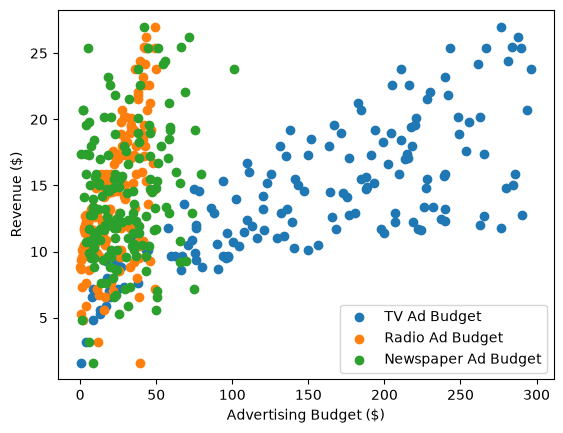

In [23]:
# Membuat plot dari dataset
plt.scatter(X_train['TV'], y_train, label='TV Ad Budget') # Changed column name to 'TV'
plt.scatter(X_train['Radio'], y_train, label='Radio Ad Budget') # Changed column name to 'Radio'
plt.scatter(X_train['Newspaper'], y_train, label='Newspaper Ad Budget') # Changed column name to 'Newspaper'
plt.xlabel('Advertising Budget ($)')
plt.ylabel('Revenue ($)')
plt.legend()
plt.show()

In [24]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

# Membangun model MLP
model = Sequential([
    Dense(512, input_shape=(3,), activation='relu'),  # Input layer
    Dense(512, activation='relu'),  # Hidden layer 1
    Dense(256, activation='relu'),  # Hidden layer 2
    Dense(1)  # Output layer (tidak perlu fungsi aktivasi karena ini masalah regresi)
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

c:\Users\ASUS\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396,289 (1.51 MB)

 Trainable params: 396,289 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)
history = model.fit(X_train, y_train, epochs=1400, validation_data=(X_test, y_test))

Epoch 1/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 140ms/step - loss: 138.2659 - mae: 9.8722 - val_loss: 84.4997 - val_mae: 8.2034
Epoch 2/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 50.0339 - mae: 5.6795 - val_loss: 13.2750 - val_mae: 2.9192
Epoch 3/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 14.0318 - mae: 3.2188 - val_loss: 8.3778 - val_mae: 2.4373
Epoch 4/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 9.3217 - mae: 2.3843 - val_loss: 7.9494 - val_mae: 2.3736
Epoch 5/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 8.0256 - mae: 2.4427 - val_loss: 7.8437 - val_mae: 2.1745
Epoch 6/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 4.5701 - mae: 1.7287 - val_loss: 7.1131 - val_mae: 2.3233
Epoch 7/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 5.0098 - mae: 1.9063 - val_loss: 6.3551 - val_mae: 2.0784
Epoch 8/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 3.0118 - mae: 1.3714 - val_loss: 4.9524 - val_mae: 1.7846
Epoch 9/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss

In [26]:
test_loss, test_mae = model.evaluate(X_test, y_test)
print(f"Mean Absolute Error pada data pengujian: {test_mae}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.6287 - mae: 0.5692
Mean Absolute Error pada data pengujian: 0.5691730380058289


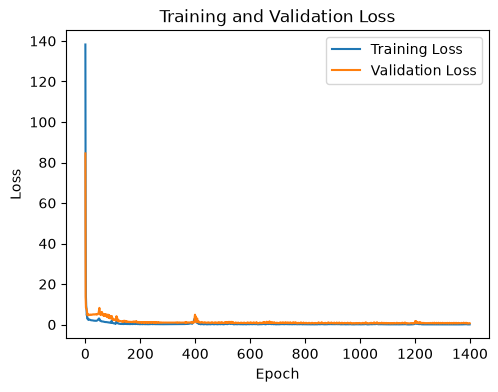

In [27]:
# Plot Loss dan MAE selama pelatihan
plt.figure(figsize=(12, 4))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step


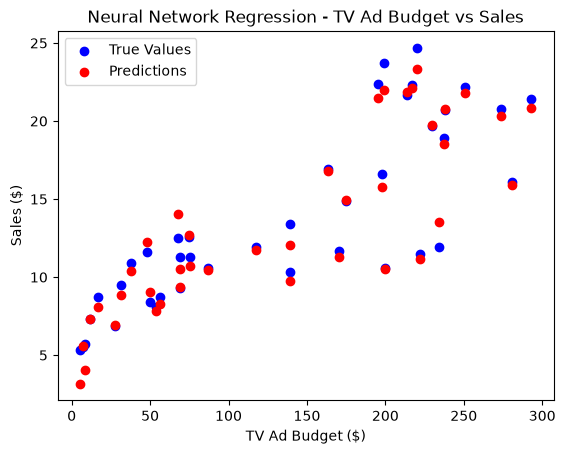

In [28]:
y_pred_test = model.predict(X_test)

plt.scatter(X_test['TV'], y_test, color='blue')

# Scatter plot of predictions (red)
plt.scatter(X_test['TV'], y_pred_test, color='red')

# Set the axis labels and title
plt.xlabel('TV Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('Neural Network Regression - TV Ad Budget vs Sales')

# Add a legend to the plot
plt.legend(['True Values', 'Predictions'])
plt.show()

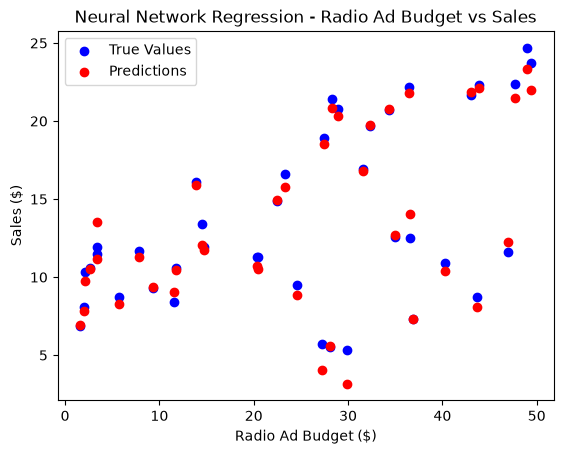

In [29]:
plt.scatter(X_test['Radio'], y_test, color='blue')

# Scatter plot of predictions (red)
plt.scatter(X_test['Radio'], y_pred_test, color='red')

# Set the axis labels and title
plt.xlabel('Radio Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('Neural Network Regression - Radio Ad Budget vs Sales')

# Add a legend to the plot
plt.legend(['True Values', 'Predictions'])
plt.show()

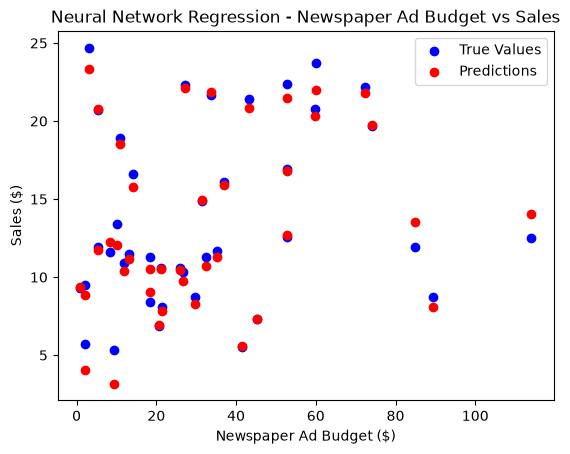

In [30]:
plt.scatter(X_test['Newspaper'], y_test, color='blue')

# Scatter plot of predictions (red)
plt.scatter(X_test['Newspaper'], y_pred_test, color='red')

# Set the axis labels and title
plt.xlabel('Newspaper Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('Neural Network Regression - Newspaper Ad Budget vs Sales')

# Add a legend to the plot
plt.legend(['True Values', 'Predictions'])
plt.show()
